In [1]:
import json
from hashlib import sha256
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path("/content")
results_dir = ROOT / "results"
results_dir.mkdir(exist_ok=True)


def locate(filename):
    for folder in (results_dir, ROOT):
        path = folder / filename
        if path.is_file():
            return path
    raise FileNotFoundError(f"Colab Dosyalar paneline yükle: {filename}")


lock_path = locate("test_predictions_locked.csv")
manifest = json.loads(locate("test_lock_manifest.json").read_text(encoding="utf-8"))
split_table = pd.read_csv(locate("dataset_split.csv"))

actual_hash = sha256(lock_path.read_bytes()).hexdigest()
expected_hash = "191a13f6f4bcaebe68e39494d20c36b31451f71ba74371f813ba552e19b5a504"

assert actual_hash == manifest["sha256"] == expected_hash, "Tahmin dosyasının hash'i değişmiş."

locked = pd.read_csv(lock_path, float_precision="round_trip")
expected_test_ids = (
    split_table.loc[split_table["split"].eq("independent_test"), "row_id"]
    .sort_values()
    .to_numpy()
)

assert locked.shape == (823, 11)
assert locked.columns.tolist() == manifest["columns"]
assert locked["row_id"].is_unique
assert np.array_equal(np.sort(locked["row_id"].to_numpy()), expected_test_ids)
assert manifest["primary_model"] == "mlp_primary"
assert manifest["threshold"] == 0.50

print("Hash doğrulandı:", actual_hash)
print("Kilitli test satırı:", len(locked))

Hash doğrulandı: 191a13f6f4bcaebe68e39494d20c36b31451f71ba74371f813ba552e19b5a504
Kilitli test satırı: 823


In [2]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    roc_auc_score,
)

test_id_set = set(expected_test_ids)
test_labels = pd.read_csv(
    locate("bank-additional.csv"),
    sep=";",
    usecols=["y"],
    skiprows=lambda line: line != 0 and (line - 1) not in test_id_set,
)

assert len(test_labels) == len(expected_test_ids)
test_labels.index = pd.Index(expected_test_ids, name="row_id")
test_labels["y"] = test_labels["y"].map({"no": 0, "yes": 1})
assert test_labels["y"].notna().all()

scored = locked.merge(
    test_labels.reset_index(), on="row_id", how="left", validate="one_to_one"
)
assert len(scored) == 823 and scored["y"].notna().all()
y_true = scored["y"].astype(int).to_numpy()
assert set(y_true) == {0, 1}

model_names = ["mlp_primary", "mlp_repeat_2", "mlp_repeat_3", "dummy", "logistic"]
metric_rows = []

for model in model_names:
    probabilities = scored[f"{model}_probability"].to_numpy()
    predictions = scored[f"{model}_prediction"].to_numpy()

    assert np.isfinite(probabilities).all()
    assert ((0 <= probabilities) & (probabilities <= 1)).all()
    assert np.array_equal(predictions, (probabilities >= manifest["threshold"]).astype(int))

    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()

    metric_rows.append({
        "model": model,
        "ap": average_precision_score(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    })

test_metrics = pd.DataFrame(metric_rows).set_index("model")
test_metrics.to_csv(results_dir / "test_metrics.csv")

print("Test sınıf sayıları:", pd.Series(y_true).value_counts().sort_index().to_dict())
display(test_metrics.round(4))

Test sınıf sayıları: {0: 731, 1: 92}


,ap,roc_auc,accuracy,precision,sensitivity,specificity,f1,balanced_accuracy,tn,fp,fn,tp
model,,,,,,,,,,,,
mlp_primary,0.3955,0.7576,0.8943,0.5862,0.1848,0.9836,0.2810,0.5842,719,12,75,17
mlp_repeat_2,0.3936,0.7376,0.8955,0.6250,0.1630,0.9877,0.2586,0.5754,722,9,77,15
mlp_repeat_3,0.3893,0.7444,0.8955,0.6154,0.1739,0.9863,0.2712,0.5801,721,10,76,16
dummy,0.1118,0.5000,0.8882,0.0000,0.0000,1.0000,0.0000,0.5000,731,0,92,0
logistic,0.3795,0.7607,0.8906,0.5238,0.2391,0.9726,0.3284,0.6059,711,20,70,22


In [3]:
primary = manifest["primary_model"]
primary_probabilities = scored[f"{primary}_probability"].to_numpy()
primary_predictions = scored[f"{primary}_prediction"].to_numpy()

bootstrap_seed = int(np.random.SeedSequence(31060).generate_state(9)[8])
rng = np.random.default_rng(bootstrap_seed)

bootstrap_rows = []
while len(bootstrap_rows) < 2000:
    idx = rng.integers(0, len(y_true), size=len(y_true))
    labels = y_true[idx]
    if np.unique(labels).size != 2:
        continue

    bootstrap_rows.append({
        "ap": average_precision_score(labels, primary_probabilities[idx]),
        "roc_auc": roc_auc_score(labels, primary_probabilities[idx]),
        "f1": f1_score(labels, primary_predictions[idx], zero_division=0),
    })

bootstrap_draws = pd.DataFrame(bootstrap_rows)
bootstrap_ci = pd.DataFrame({
    "estimate": test_metrics.loc[primary, bootstrap_draws.columns],
    "ci_95_lower": bootstrap_draws.quantile(0.025),
    "ci_95_upper": bootstrap_draws.quantile(0.975),
})
bootstrap_ci.index.name = "metric"
bootstrap_ci["bootstrap_samples"] = len(bootstrap_draws)

metric_columns = [
    "ap", "roc_auc", "accuracy", "precision", "sensitivity",
    "specificity", "f1", "balanced_accuracy",
]
seed_results = test_metrics.loc[
    ["mlp_primary", "mlp_repeat_2", "mlp_repeat_3"], metric_columns
].copy()
seed_summary = seed_results.agg(["mean", "std"]).T

bootstrap_ci.to_csv(results_dir / "test_bootstrap_ci.csv")
seed_results.to_csv(results_dir / "seed_stability_results.csv")
seed_summary.to_csv(results_dir / "seed_stability_summary.csv")

display(bootstrap_ci.round(4))
display(seed_summary.round(4))

,estimate,ci_95_lower,ci_95_upper,bootstrap_samples
metric,,,,
ap,0.3955,0.3027,0.5030,2000
roc_auc,0.7576,0.6971,0.8153,2000
f1,0.2810,0.1719,0.3830,2000


,mean,std
ap,0.3928,0.0031
roc_auc,0.7465,0.0102
accuracy,0.8951,0.0007
precision,0.6089,0.0202
sensitivity,0.1739,0.0109
specificity,0.9859,0.0021
f1,0.2703,0.0112
balanced_accuracy,0.5799,0.0044


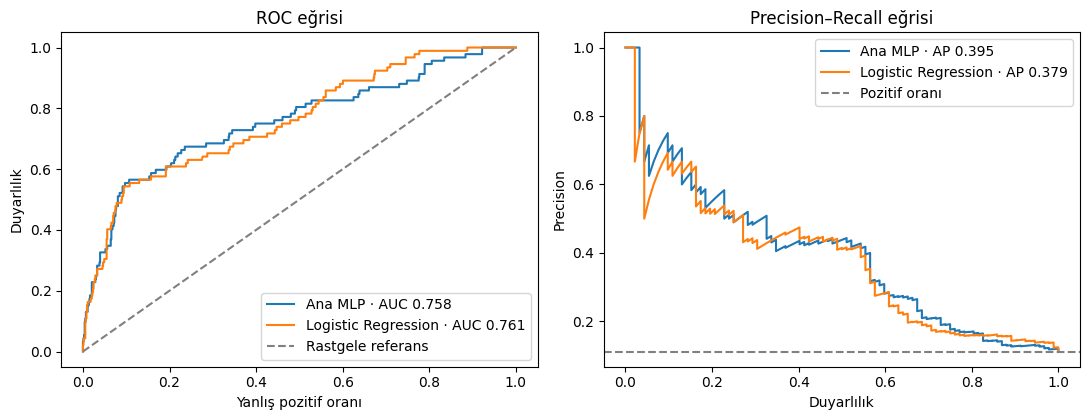

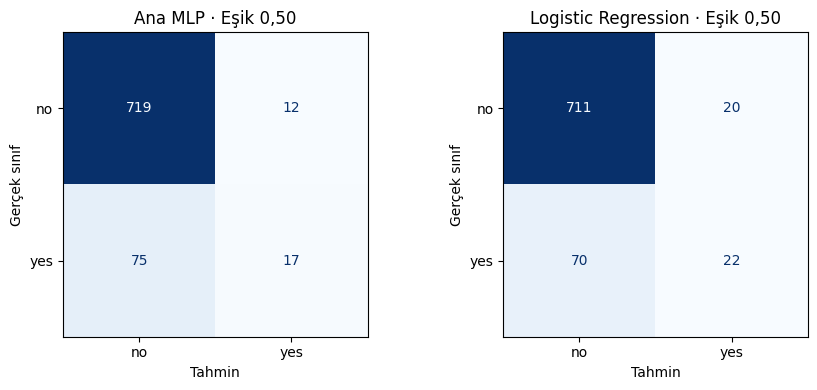

,count,min_probability,median_probability,max_probability,share_of_actual_class
error_type,,,,,
FN,75,0.0310,0.1302,0.4677,0.8152
FP,12,0.5172,0.6106,0.7447,0.0164


In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
)

figures_dir = ROOT / "figures"
figures_dir.mkdir(exist_ok=True)


def save_test_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(figures_dir / f"{filename}.svg", bbox_inches="tight")
    fig.savefig(figures_dir / f"{filename}.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


comparison_models = {
    "mlp_primary": "Ana MLP",
    "logistic": "Logistic Regression",
}

fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(11, 4.3))

for name, label in comparison_models.items():
    probabilities = scored[f"{name}_probability"].to_numpy()
    fpr, tpr, _ = roc_curve(y_true, probabilities)
    precision, recall, _ = precision_recall_curve(y_true, probabilities)

    roc_auc_value = test_metrics.loc[name, "roc_auc"]
    ap_value = test_metrics.loc[name, "ap"]
    roc_ax.plot(fpr, tpr, label=f"{label} · AUC {roc_auc_value:.3f}")
    pr_ax.plot(recall, precision, label=f"{label} · AP {ap_value:.3f}")

roc_ax.plot([0, 1], [0, 1], "--", color="gray", label="Rastgele referans")
pr_ax.axhline(y_true.mean(), linestyle="--", color="gray", label="Pozitif oranı")
roc_ax.set(title="ROC eğrisi", xlabel="Yanlış pozitif oranı", ylabel="Duyarlılık")
pr_ax.set(title="Precision–Recall eğrisi", xlabel="Duyarlılık", ylabel="Precision")

for ax in (roc_ax, pr_ax):
    ax.legend(loc="best")

save_test_figure(fig, "test_roc_pr_curves")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, (name, label) in zip(axes, comparison_models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        scored[f"{name}_prediction"],
        labels=[0, 1],
        display_labels=["no", "yes"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set(
        title=f"{label} · Eşik 0,50",
        xlabel="Tahmin",
        ylabel="Gerçek sınıf",
    )

save_test_figure(fig, "test_confusion_matrices")

errors = scored.loc[
    scored["y"].ne(scored[f"{primary}_prediction"]),
    ["row_id", "y", f"{primary}_prediction", f"{primary}_probability"],
].copy()
errors = errors.rename(columns={
    f"{primary}_prediction": "prediction",
    f"{primary}_probability": "probability",
})
errors["error_type"] = np.where(errors["y"].eq(1), "FN", "FP")

error_summary = errors.groupby("error_type").agg(
    count=("row_id", "size"),
    min_probability=("probability", "min"),
    median_probability=("probability", "median"),
    max_probability=("probability", "max"),
)
error_summary["share_of_actual_class"] = (
    error_summary["count"] / pd.Series({"FN": y_true.sum(), "FP": (y_true == 0).sum()})
)

errors.to_csv(results_dir / "test_primary_errors.csv", index=False)
error_summary.to_csv(results_dir / "test_primary_error_summary.csv")
display(error_summary.round(4))